# CM2 vs OM2: trend comparison (winds & radiation)

**What's in this notebook**

- Compares ERA5 / JRA55-do trends against ACCESS-CM2.
- Fields: uas, vas, rsds, rlds, huss, tas.

_Split from `plots_cm2_om2_compare.ipynb`. Shared helpers in `functions.py`; outputs stripped — re-run to regenerate figures._


In [2]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [3]:
import sys, os
# make this repo's functions.py importable from any subfolder
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *  # shared helper functions


In [4]:
# Load variables produced by earlier (compute/loader) notebooks.
# Run those first; harmless if there's nothing saved yet.
load_state(globals())


[load_state] loaded 251 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, axes, base_path, basin_cmip, basin_era5, basin_jra55 ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

# plots cm2 om2 compare

In [5]:
# Load Packages 

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import math
import cartopy.crs as ccrs
import calendar
from matplotlib.lines import Line2D
import os
import re
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm
# from mpl_toolkits.basemap import Basemap
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from scipy.stats import scoreatpercentile
# import xesmf as xe
from matplotlib.gridspec import GridSpec
import matplotlib

%matplotlib inline


In [7]:
# base 
base_path = '/Users/isabelaconde/Desktop/data/ERA5_JRA55-do_trends/'

# ERA5 files 
era5_uas = xr.open_dataarray(base_path + 'ERA5_u10_trend_1982-2018_gr.nc').sel(lon = slice(110,300))
era5_vas = xr.open_dataarray(base_path + 'ERA5_v10_trend_1982-2018_gr.nc').sel(lon = slice(110,300))
era5_tas = xr.open_dataarray(base_path + 'ERA5_tas_trend_1982-2018_gr.nc').sel(lon = slice(110,300))
era5_huss = xr.open_dataarray(base_path + 'ERA5_huss_trend_1982-2018_gr.nc').sel(lon = slice(110,300))
era5_rsds = xr.open_dataarray(base_path + 'ERA5_rsds_trend_1982-2018_gr.nc').sel(lon = slice(110,300))
era5_rlds = xr.open_dataarray(base_path + 'ERA5_rlds_trend_1982-2018_gr.nc').sel(lon = slice(110,300))

# JRA55-do files

jra55_uas = xr.open_dataarray(base_path + 'JRA55-do_uas-trend_1982-2018_gr.nc').sel(lon = slice(110,300))
jra55_vas = xr.open_dataarray(base_path + 'JRA55-do_vas-trend_1982-2018_gr.nc').sel(lon = slice(110,300))
jra55_tas = xr.open_dataarray(base_path + 'JRA55-do_tas-trend_1982-2018_gr.nc').sel(lon = slice(110,300))
jra55_huss = xr.open_dataarray(base_path + 'JRA55-do_huss-trend_1982-2018_gr.nc').sel(lon = slice(110,300))
jra55_rsds = xr.open_dataarray(base_path + 'JRA55-do_rsds-trend_1982-2018_gr.nc').sel(lon = slice(110,300))
jra55_rlds = xr.open_dataarray(base_path + 'JRA55-do_rlds-trend_1982-2018_gr.nc').sel(lon = slice(110,300))




In [14]:
# Save this notebook's variables so later (plotting) notebooks can load them.
save_state(globals())


[save_state] saved 251 variables -> /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl


'/Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl'

# ERA5 vs. JRA55-do plots 

- combine to make one plot 

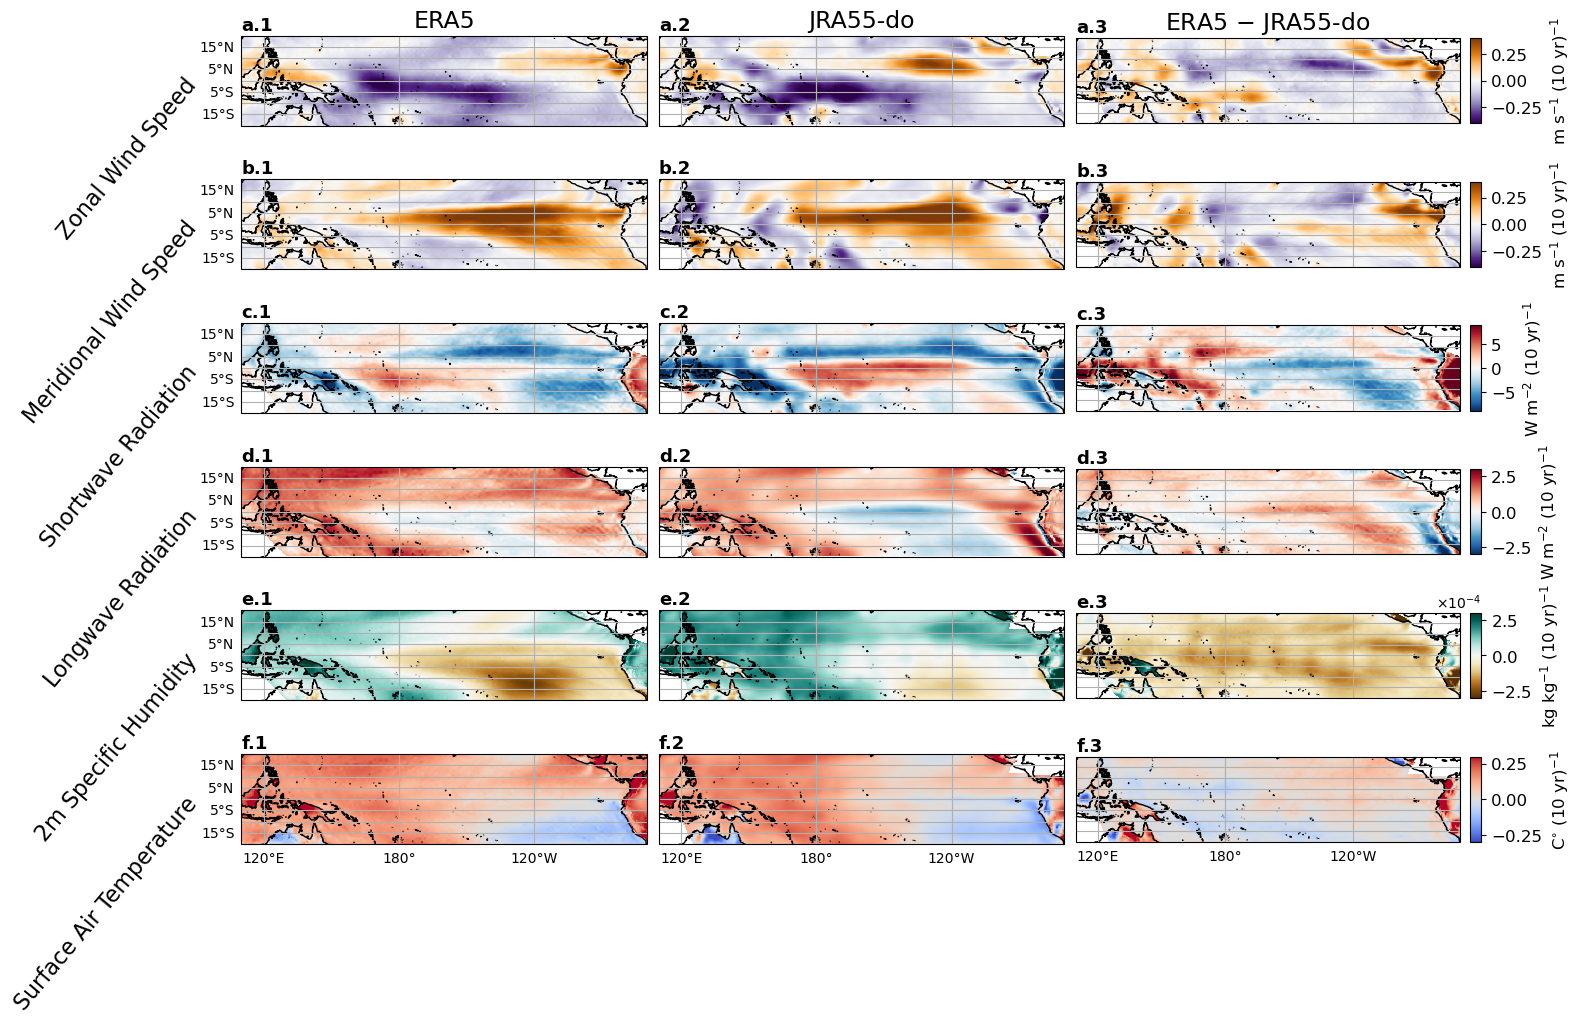

In [15]:
# =========================================================
# Combined figure: all six fields (rows) x ERA5 / JRA55-do / ERA5 - JRA55-do (cols)
# Rows follow the same order as the individual plots above.
# =========================================================
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.axes as maxes

proj   = ccrs.PlateCarree(central_longitude=180)
pc0    = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

# one entry per field (row) -- same order as the single-field plots above
fields = [
    dict(name="Zonal Wind Speed",                era5=era5_uas,  jra55=jra55_uas,
         cmap="PuOr_r", v=0.4,    cbar=r'm s$^{-1}$ (10 yr)$^{-1}$'),
    dict(name="Meridional Wind Speed",           era5=era5_vas,  jra55=jra55_vas,
         cmap="PuOr_r", v=0.4,    cbar=r'm s$^{-1}$ (10 yr)$^{-1}$'),
    dict(name="Shortwave Radiation", era5=era5_rsds, jra55=jra55_rsds,
         cmap="RdBu_r", v=9,      cbar=r'W m$^{-2}$ (10 yr)$^{-1}$'),
    dict(name="Longwave Radiation",  era5=era5_rlds, jra55=jra55_rlds,
         cmap="RdBu_r", v=3,      cbar=r'W m$^{-2}$ (10 yr)$^{-1}$'),
    dict(name="2m Specific Humidity",            era5=era5_huss, jra55=jra55_huss,
         cmap="BrBG", v=0.0003, cbar=r'kg kg$^{-1}$ (10 yr)$^{-1}$', sci=True),
    dict(name="Surface Air Temperature",         era5=era5_tas,  jra55=jra55_tas,
         cmap="coolwarm", v=0.3,    cbar=r'C$^{\circ}$ (10 yr)$^{-1}$'),
]

col_titles = ["ERA5", "JRA55-do", r"ERA5 $-$ JRA55-do"]
nrows = len(fields)

fig = plt.figure(figsize=(16, 11))
gs  = GridSpec(nrows, 3, figure=fig, wspace=0.03, hspace=0.12)

for r, f in enumerate(fields):
    lat, lon = f["era5"].lat, f["era5"].lon
    era5  = f["era5"]
    jra55 = f["jra55"].interp(lat=lat, lon=lon)

    das = [
        era5 * 10 * 12,
        jra55 * 10 * 12 * 30 * 8,
        (era5 - jra55 * 30 * 8) * 10 * 12,
    ]
    vmin, vmax = -f["v"], f["v"]

    for c in range(3):
        ax = fig.add_subplot(gs[r, c], projection=proj)
        im = ax.pcolormesh(das[c].lon, das[c].lat, das[c],
                           cmap=f["cmap"], vmin=vmin, vmax=vmax, transform=pc0)
        ax.set_extent(extent, crs=pc0)
        ax.coastlines()

        # panel label (a.1, a.2, a.3, b.1, ...) above the panel
        ax.text(0.0, 1.02, f"{chr(97 + r)}.{c + 1}", transform=ax.transAxes,
                va="bottom", ha="left", fontsize=13, fontweight="bold")

        # column headers on the top row only
        if r == 0:
            ax.set_title(col_titles[c], fontsize=17)

        # gridlines: y-labels only on left column, x-labels only on bottom row
        gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.top_labels = False
        gl.right_labels = False
        if c != 0:
            gl.left_labels = False
        if r != nrows - 1:
            gl.bottom_labels = False

        # field name as an angled row label on the left column
        if c == 0:
            ax.text(-0.12, 0.5, f["name"], transform=ax.transAxes,
                    rotation=50, rotation_mode="anchor",
                    va="center", ha="right", fontsize=16)

        # per-row colorbar (matched to map height) beside the difference panel
        if c == 2:
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="3%", pad=0.1, axes_class=maxes.Axes)
            cb = fig.colorbar(im, cax=cax)
            cb.set_label(f["cbar"], fontsize=12)
            cb.ax.tick_params(labelsize=12)
            if f.get("sci"):
                cb.formatter.set_powerlimits((0, 0))
                cb.formatter.set_useMathText(True)
                cb.update_ticks()

fig.savefig("/Users/isabelaconde/Desktop/era5_jra55do_trends.png",
            dpi=300, bbox_inches="tight")
plt.show()


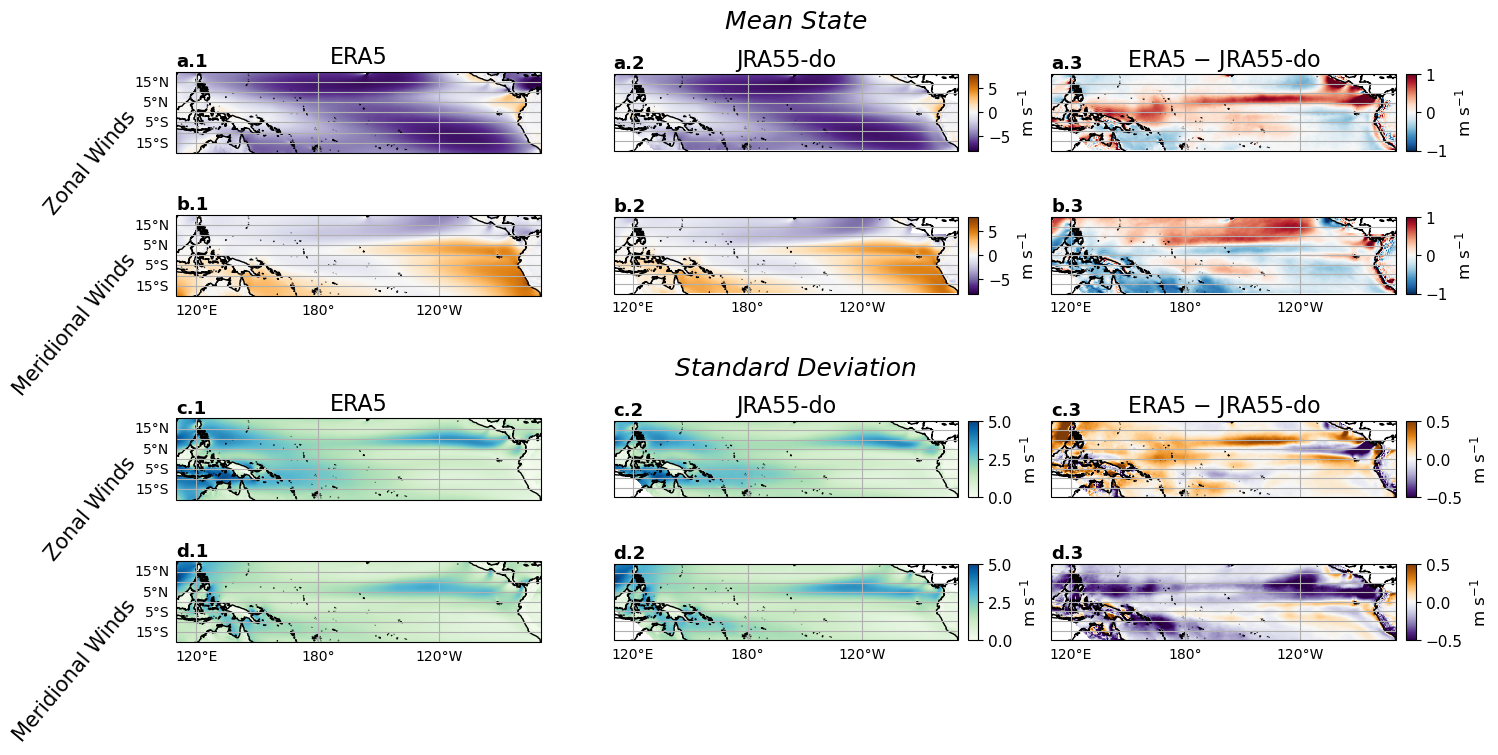

In [16]:
# =========================================================
# Mean state & standard deviation of surface winds: ERA5 vs JRA55-do
# Single figure: 2 sections (Mean State, Standard Deviation), each 2 rows
#                (zonal, meridional) x 3 cols (ERA5, JRA55-do, ERA5 - JRA55-do)
#   Mean state : ready-made means (/ERA5/mean, /JRA55/means)
#   Std        : temporal std of the monthly time series, 1982-2017, both datasets
# # =========================================================
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.axes as maxes

era5_mean_dir = "/Users/isabelaconde/Desktop/data/ERA5/mean/"
jra_mean_dir  = "/Users/isabelaconde/Desktop/data/JRA55/means/"
ts_dir        = "/Users/isabelaconde/Desktop/data/mnthly_avg_era5_jra55/"

# ---- mean state (ready-made 2-D means) ----
era5_mean_u = xr.open_dataarray(era5_mean_dir + "ERA5_u10_mean_1982-2018_gr.nc").sel(lon=slice(110, 300))
era5_mean_v = xr.open_dataarray(era5_mean_dir + "ERA5_v10_mean_1982-2018_gr.nc").sel(lon=slice(110, 300))
jra_mean_u  = xr.open_dataarray(jra_mean_dir  + "JRA55-do_uas-mean_1982-2018_gr.nc")
jra_mean_v  = xr.open_dataarray(jra_mean_dir  + "JRA55-do_vas-mean_1982-2018_gr.nc")

# common target grid = ERA5 mean grid
tlat, tlon = era5_mean_u.lat, era5_mean_u.lon
on_grid = lambda da: da.interp(lat=tlat, lon=tlon)

# ---- standard deviation of the monthly time series (1982-2017), both datasets ----
t0, t1 = "1982", "2017"

era5_u_ts = xr.open_dataarray(ts_dir + "ERA5_uas_monthly_1982-2018_gr.nc").sortby("lat").sel(lat=slice(-20, 20), lon=slice(110, 300)).sel(time=slice(t0, t1))
era5_v_ts = xr.open_dataarray(ts_dir + "ERA5_vas_monthly_1982-2018_gr.nc").sortby("lat").sel(lat=slice(-20, 20), lon=slice(110, 300)).sel(time=slice(t0, t1))
era5_std_u = era5_u_ts.std("time")
era5_std_v = era5_v_ts.std("time")

jra_u_ts = xr.open_dataarray(ts_dir + "JRA55-do_uas-monthly_1982-2018_gr.nc").sel(time=slice(t0, t1))
jra_v_ts = xr.open_dataarray(ts_dir + "JRA55-do_vas-monthly_1982-2018_gr.nc").sel(time=slice(t0, t1))
jra_std_u = jra_u_ts.std("time")
jra_std_v = jra_v_ts.std("time")

# ---- figure ----
proj   = ccrs.PlateCarree(central_longitude=180)
pc0    = ccrs.PlateCarree()
extent = [110, 290, -20, 20]
col_titles = ["ERA5", "JRA55-do", r"ERA5 $-$ JRA55-do"]

# rows top-to-bottom; gsr = gridspec row index (row 2 is a spacer between sections)
rows = [
    dict(gsr=0, letter="a", section="Mean State", name="Zonal Winds",
         era5=era5_mean_u, jra=jra_mean_u,
         cmap="PuOr_r", vmin=-8, vmax=8, dcmap="RdBu_r", dvmin=-1, dvmax=1,
         cbar=r"m s$^{-1}$", header=True, xlabels=False),
    dict(gsr=1, letter="b", section=None, name="Meridional Winds",
         era5=era5_mean_v, jra=jra_mean_v,
         cmap="PuOr_r", vmin=-8, vmax=8, dcmap="RdBu_r", dvmin=-1, dvmax=1,
         cbar=r"m s$^{-1}$", header=False, xlabels=True),
    dict(gsr=3, letter="c", section="Standard Deviation", name="Zonal Winds",
         era5=era5_std_u, jra=jra_std_u,
         cmap="GnBu", vmin=0, vmax=5, dcmap="PuOr_r", dvmin=-0.5, dvmax=0.5,
         cbar=r"m s$^{-1}$", header=True, xlabels=False),
    dict(gsr=4, letter="d", section=None, name="Meridional Winds",
         era5=era5_std_v, jra=jra_std_v,
         cmap="GnBu", vmin=0, vmax=5, dcmap="PuOr_r", dvmin=-0.5, dvmax=0.5,
         cbar=r"m s$^{-1}$", header=False, xlabels=True),
]

fig = plt.figure(figsize=(16, 8))
gs  = GridSpec(5, 3, figure=fig, wspace=0.2, hspace=0.15,
               height_ratios=[1, 1, 0.35, 1, 1])   # row 2 = gap between sections

for row in rows:
    era5 = on_grid(row["era5"])
    jra  = on_grid(row["jra"])
    das  = [era5, jra, era5 - jra]

    # section title, centred over the 3 columns, above this row's cell
    if row["section"]:
        band = gs[row["gsr"], :].get_position(fig)
        fig.text((band.x0 + band.x1) / 2, band.y1 + 0.02, row["section"],
                 ha="center", va="bottom", fontsize=18,  fontstyle="italic")

    for c in range(3):
        ax = fig.add_subplot(gs[row["gsr"], c], projection=proj)
        if c < 2:                        # ERA5 & JRA55-do share a scale
            cmap, vmin, vmax = row["cmap"], row["vmin"], row["vmax"]
        else:                            # difference column
            cmap, vmin, vmax = row["dcmap"], row["dvmin"], row["dvmax"]
        im = ax.pcolormesh(das[c].lon, das[c].lat, das[c],
                           cmap=cmap, vmin=vmin, vmax=vmax, transform=pc0)
        ax.set_extent(extent, crs=pc0)
        ax.coastlines()

        # panel label a.1, a.2, ... above the panel
        ax.text(0.0, 1.02, f"{row['letter']}.{c + 1}", transform=ax.transAxes,
                va="bottom", ha="left", fontsize=13, fontweight = 'bold')

        # column headers on the first row of each section
        if row["header"]:
            ax.set_title(col_titles[c], fontsize=16)

        # gridlines: y-labels only on left column, x-labels only on section-bottom rows
        gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.top_labels = False
        gl.right_labels = False
        if c != 0:
            gl.left_labels = False
        if not row["xlabels"]:
            gl.bottom_labels = False

        # angled side label on the left column
        if c == 0:
            ax.text(-0.12, 0.5, row["name"], transform=ax.transAxes,
                    rotation=50, rotation_mode="anchor",
                    va="center", ha="right",fontsize=15)

        # shared colorbar after col 1; difference colorbar after col 2
        if c in (1, 2):
            cax = make_axes_locatable(ax).append_axes(
                "right", size="3%", pad=0.1, axes_class=maxes.Axes)
            cb = fig.colorbar(im, cax=cax)
            cb.set_label(row["cbar"], fontsize=12)
            cb.ax.tick_params(labelsize=11)

fig.savefig("/Users/isabelaconde/Desktop/wind_mean_std.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [17]:
# # =========================================================
# # ERA5 - JRA55-do differences: mean state & standard deviation of surface winds
# # 2 rows (zonal, meridional) x 2 cols (Mean State, Standard Deviation)
# # =========================================================
# era5_mean_dir = "/Users/isabelaconde/Desktop/data/ERA5/mean/"
# jra_mean_dir  = "/Users/isabelaconde/Desktop/data/JRA55/means/"
# ts_dir        = "/Users/isabelaconde/Desktop/data/mnthly_avg_era5_jra55/"

# # ---- mean state (ready-made 2-D means) ----
# era5_mean_u = xr.open_dataarray(era5_mean_dir + "ERA5_u10_mean_1982-2018_gr.nc").sel(lon=slice(110, 300))
# era5_mean_v = xr.open_dataarray(era5_mean_dir + "ERA5_v10_mean_1982-2018_gr.nc").sel(lon=slice(110, 300))
# jra_mean_u  = xr.open_dataarray(jra_mean_dir  + "JRA55-do_uas-mean_1982-2018_gr.nc")
# jra_mean_v  = xr.open_dataarray(jra_mean_dir  + "JRA55-do_vas-mean_1982-2018_gr.nc")

# # common target grid = ERA5 mean grid
# tlat, tlon = era5_mean_u.lat, era5_mean_u.lon
# on_grid = lambda da: da.interp(lat=tlat, lon=tlon)

# # ---- standard deviation of the monthly time series (1982-2017), both datasets ----
# t0, t1 = "1982", "2017"

# era5_u_ts = xr.open_dataarray(ts_dir + "ERA5_uas_monthly_1982-2018_gr.nc").sortby("lat").sel(lat=slice(-20, 20), lon=slice(110, 300)).sel(time=slice(t0, t1))
# era5_v_ts = xr.open_dataarray(ts_dir + "ERA5_vas_monthly_1982-2018_gr.nc").sortby("lat").sel(lat=slice(-20, 20), lon=slice(110, 300)).sel(time=slice(t0, t1))
# era5_std_u = era5_u_ts.std("time")
# era5_std_v = era5_v_ts.std("time")

# jra_u_ts = xr.open_dataarray(ts_dir + "JRA55-do_uas-monthly_1982-2018_gr.nc").sel(time=slice(t0, t1))
# jra_v_ts = xr.open_dataarray(ts_dir + "JRA55-do_vas-monthly_1982-2018_gr.nc").sel(time=slice(t0, t1))
# jra_std_u = jra_u_ts.std("time")
# jra_std_v = jra_v_ts.std("time")

# # ---- ERA5 - JRA55-do differences (on the common ERA5 grid) ----
# mean_u_diff = on_grid(era5_mean_u) - on_grid(jra_mean_u)
# mean_v_diff = on_grid(era5_mean_v) - on_grid(jra_mean_v)
# std_u_diff  = on_grid(era5_std_u)  - on_grid(jra_std_u)
# std_v_diff  = on_grid(era5_std_v)  - on_grid(jra_std_v)

# ---- figure ----
proj   = ccrs.PlateCarree(central_longitude=180)
pc0    = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

# rows = wind component, cols = quantity (both are ERA5 - JRA55-do differences)
rows = [
    dict(name="Zonal Winds",      mean=mean_u_diff, std=std_u_diff, xlabels=False),
    dict(name="Meridional Winds", mean=mean_v_diff, std=std_v_diff, xlabels=True),
]
cols = [
    dict(title="Mean State",         key="mean", cmap="RdBu_r", vmin=-1,   vmax=1),
    dict(title="Standard Deviation", key="std",  cmap="PuOr_r", vmin=-0.5, vmax=0.5),
]

fig = plt.figure(figsize=(15, 4))
gs  = GridSpec(2, 2, figure=fig, wspace=0.2, hspace=0.05)

col_axes = {0: [], 1: []}   # axes per column (for a shared colorbar spanning both rows)
col_im   = {}               # one image per column (all share the column's scale)

for r, row in enumerate(rows):
    for c, col in enumerate(cols):
        ax = fig.add_subplot(gs[r, c], projection=proj)
        da = row[col["key"]]
        im = ax.pcolormesh(da.lon, da.lat, da, cmap=col["cmap"],
                           vmin=col["vmin"], vmax=col["vmax"], transform=pc0)
        ax.set_extent(extent, crs=pc0)
        ax.coastlines()

        # panel label a, b, c, d above the panel
        ax.text(0.0, 1.02, f"{chr(97 + r * 2 + c)}", transform=ax.transAxes,
                va="bottom", ha="left", fontsize=13, fontweight="bold")

        # column titles on the top row only
        if r == 0:
            ax.set_title(col["title"], fontsize=16)

        # gridlines: y-labels only on left column, x-labels only on bottom row
        gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.top_labels = False
        gl.right_labels = False
        if c != 0:
            gl.left_labels = False
        if not row["xlabels"]:
            gl.bottom_labels = False

        # angled side label on the left column
        if c == 0:
            ax.text(-0.12, 0.5, row["name"], transform=ax.transAxes,
                    rotation=50, rotation_mode="anchor",
                    va="center", ha="right", fontsize=15)

        col_axes[c].append(ax)
        col_im[c] = im

# one colorbar per column, spanning the height of both rows
for c in (0, 1):
    cb = fig.colorbar(col_im[c], ax=col_axes[c], fraction=0.025, pad=0.02)
    cb.set_label(r"m s$^{-1}$", fontsize=12)
    cb.ax.tick_params(labelsize=11)

plt.suptitle(r"ERA5 $-$ JRA55-do Difference", fontsize=18, y=0.98)

fig.savefig("/Users/isabelaconde/Desktop/wind_diff_mean_std.png",
            dpi=300, bbox_inches="tight")
plt.show()

NameError: name 'mean_u_diff' is not defined

In [ ]:
# Source - https://stackoverflow.com/a/74831123
# Posted by C.K., modified by community. See post 'Timeline' for change history
# Retrieved 2026-08-05, License - CC BY-SA 4.0

import matplotlib.colors as mcolors
import numpy as np
from sklearn.neighbors import NearestNeighbors

class NearestColorNames:
    def __init__(self,n_neighbors=3):
        cnames = mcolors.CSS4_COLORS
        self.names = np.array(list(cnames.keys()))
        rgb_arr = np.array([mcolors.to_rgb(hex) for hex in cnames.values()])
        self.knn = NearestNeighbors(n_neighbors=n_neighbors)
        self.knn.fit(rgb_arr)
    
    def get_nearest_rgb(self,rgb_tpl,return_string=False):
        dists,ids = self.knn.kneighbors([rgb_tpl])
        names = self.names[ids[0]]
        result = {
            name:dist
            for name,dist in zip(names,dists[0])
        }
        if return_string:
            return ", ".join([f"{name}({dist:.3f})" for name,dist in result.items()])
        else:
            return result
    
    def get_nearest_hex(self,hex_code,return_string=False):
        if not hex_code.startswith("#"):
            hex_code = "#"+hex_code
        return self.get_nearest_rgb(mcolors.to_rgb(hex_code),return_string=return_string)


In [ ]:
# Source - https://stackoverflow.com/a/74831123
# Posted by C.K., modified by community. See post 'Timeline' for change history
# Retrieved 2026-08-05, License - CC BY-SA 4.0

colors = ['firebrick', 'darkviolet', 'cyan', 'b', 'violet', 'orange', 'limegreen', 'k']

colors = ['#B22222', '#9400D3', '#00FFFF', '#0000FF', '#EE82EE', '#FFA500', '#32CD32', '#000000']
names_picker = NearestColorNames(3)
for color in ['#B22222', '#9400D3', '#00FFFF', '#0000FF', '#EE82EE', '#FFA500', '#32CD32', '#000000']:
    names = names_picker.get_nearest_hex(color,return_string=True)
    print(color,names)


#B22222 firebrick(0.000), brown(0.068), crimson(0.201)
#9400D3 darkviolet(0.000), blueviolet(0.183), darkorchid(0.199)
#00FFFF aqua(0.000), cyan(0.000), deepskyblue(0.251)
#0000FF blue(0.000), mediumblue(0.196), darkblue(0.455)
#EE82EE violet(0.000), orchid(0.141), plum(0.151)
#FFA500 orange(0.000), darkorange(0.098), goldenrod(0.192)
#32CD32 limegreen(0.000), mediumseagreen(0.270), forestgreen(0.274)
#000000 black(0.000), darkgreen(0.392), midnightblue(0.461)


# P3 exp plots

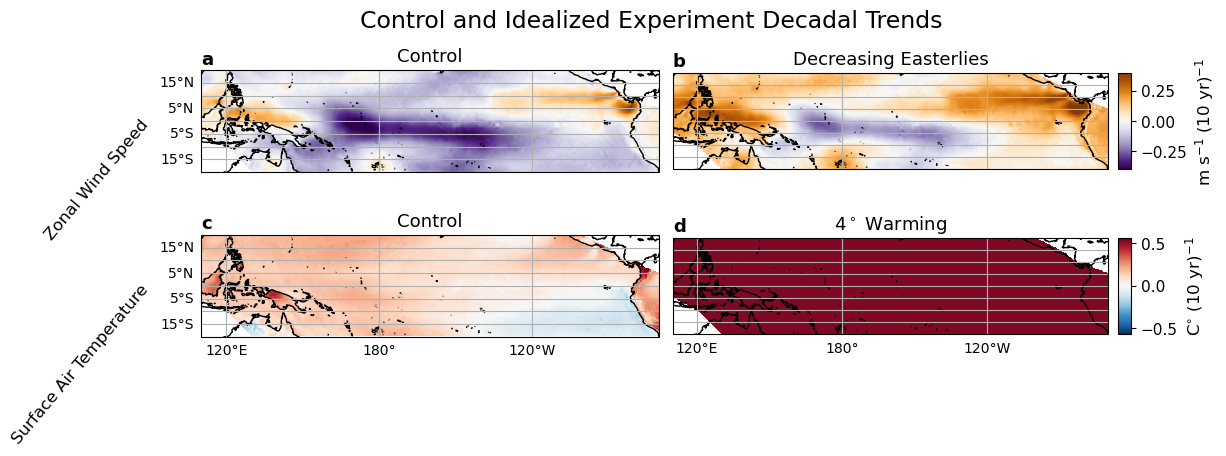

In [37]:
proj   = ccrs.PlateCarree(central_longitude=180)
pc0    = ccrs.PlateCarree()
extent = [110, 290, -20, 20]

# ERA5 trend fields (per 10 yr)
uas_trend = pacific_mask(era5_uas)*era5_uas * 10 * 12
tas_trend = pacific_mask(era5_tas)*era5_tas * 10 * 12

# rows: (field name, [col1 field, col2 field], cmap, vlim, cbar label)
rows = [
    dict(name="Zonal Wind Speed",
         das=[uas_trend, uas_trend + 0.15],
         titles=["Control", r"Decreasing Easterlies"],
         cmap="PuOr_r", v=0.4, cbar=r'm s$^{-1}$ (10 yr)$^{-1}$'),
    dict(name="Surface Air Temperature",
         das=[tas_trend, tas_trend * 0 + 0.53],
         titles=["Control", r"$4^\circ$ Warming"],
         cmap="RdBu_r", v=0.57, cbar=r'C$^{\circ}$ (10 yr)$^{-1}$'),
]

fig = plt.figure(figsize=(12, 4))
gs  = GridSpec(2, 2, figure=fig, wspace=0.03, hspace=0.15)

for r, row in enumerate(rows):
    vmin, vmax = -row["v"], row["v"]
    for c in range(2):
        da = row["das"][c]
        ax = fig.add_subplot(gs[r, c], projection=proj)
        im = ax.pcolormesh(da.lon, da.lat, da,
                           cmap=row["cmap"], vmin=vmin, vmax=vmax, transform=pc0)
        ax.set_extent(extent, crs=pc0)
        ax.coastlines()

        # panel title
        ax.set_title(row["titles"][c], fontsize=13)

        # panel label (a, b, c, d)
        ax.text(0.0, 1.02, f"{chr(97 + r*2 + c)}", transform=ax.transAxes,
                va="bottom", ha="left", fontsize=13, fontweight="bold")

        # gridlines: y-labels left col only, x-labels bottom row only
        gl = ax.gridlines(draw_labels=True, x_inline=False, y_inline=False)
        gl.top_labels = False
        gl.right_labels = False
        if c != 0:
            gl.left_labels = False
        if r != len(rows) - 1:
            gl.bottom_labels = False

        # row label (field name) on the left column
        if c == 0:
            ax.text(-0.12, 0.5, row["name"], transform=ax.transAxes,
                    rotation=50, rotation_mode="anchor",
                    va="center", ha="right", fontsize=12)

        # per-row colorbar beside the right panel
        if c == 1:
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="3%", pad=0.1, axes_class=maxes.Axes)
            cb = fig.colorbar(im, cax=cax)
            cb.set_label(row["cbar"], fontsize=12)
            cb.ax.tick_params(labelsize=11)

fig.suptitle("Control and Idealized Experiment Decadal Trends",
             fontsize=17, y=0.98)

fig.savefig("/Users/isabelaconde/Desktop/era5_uas_tas_2x2.png",
            dpi=300, bbox_inches="tight")